# ДЗ-1. Рекомендательные системы на Steam V2

**Кривцов Илья Андреевич**

Сравниваю ItemKNN, iALS, EASE, FM и RecencyALS. По прошлым отзывам нужно рекомендовать 10 игр вне истории пользователя.

Релевантна игра, о которой пользователь оставит отзыв в отложенном периоде, независимо от оценки.

## 1. Запуск

Нужны Linux, Python 3.10-3.12 и `curl`. Для Ubuntu/Debian:

```bash
sudo apt install python3 python3-venv python3-pip curl ca-certificates
```

Из корня репозитория:

```bash
bash hw1/run.sh
```

Скрипт создаёт `hw1/.venv`, устанавливает зависимости, скачивает данные и выполняет ноутбук на CPU. Архив отзывов занимает около 1,3 ГБ. Данные сохраняются в `hw1/data/`, результаты - в `hw1/artifacts/`.

Повторный запуск без установки пакетов: `bash hw1/run.sh --skip-install`.

In [1]:
from pathlib import Path
import json
import io
from contextlib import redirect_stdout
import platform
import random
import sys

import numpy as np
import pandas as pd
import torch
from scipy import sparse
from IPython.display import display, Markdown, Image

ROOT = Path.cwd().resolve()
if not (ROOT / "config.json").exists():
    ROOT = ROOT / "hw1"
if not (ROOT / "config.json").exists():
    raise RuntimeError("Запустите ноутбук из корня репозитория или каталога hw1")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data import download, prepare_data, build_item_features
from src.experiments import (
    read_json, run_validation, run_final, generate_figures,
    matrices, truth_matrix, fingerprint,
)
from src.reporting import make_figures

CONFIG = read_json(ROOT / "config.json")
SEED = CONFIG["seed"]
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.max_rows", 100)
display(pd.DataFrame([{
    "Python": platform.python_version(), "NumPy": np.__version__,
    "PyTorch": torch.__version__, "seed": SEED, "CPU threads": 2,
}]))

,Python,NumPy,PyTorch,seed,CPU threads
0,3.10.11,2.2.6,2.12.0+cu130,42,2


## 2. Данные и подготовка

[Steam V2](https://github.com/kang205/SASRec#steam-dataset) содержит отзывы пользователей и описания игр. Из 7 793 069 отзывов после очистки и отбора осталось 347 050 взаимодействий, 20 000 пользователей и 3 498 игр. Подвыборка ограничивает время обучения и полного ранжирования.

Основные поля: `user_id` - пользователь, `product_id` - игра, `date` - дата отзыва, `hours` - накопленное время игры. Использую только явные 17-значные Steam ID: никнеймы не позволяют однозначно различить пользователей. ID заменены хешами, тексты отзывов не используются.

In [2]:
with redirect_stdout(io.StringIO()):
    download(ROOT)

data = prepare_data(ROOT, **CONFIG["data"])

### Очистка и подвыборка

1. Удаляю записи без корректных ID и даты. Ошибочные `hours` заменяю пропусками.
2. Для повторных пар пользователь-игра сохраняю самый ранний отзыв.
3. Границы train, validation и test задаю по квантилям дат 70% и 85%. Отзывы одного дня не разделяю.
4. По train выбираю до 3500 популярных игр с метаданными и до 20 000 наиболее активных пользователей с минимум тремя train-взаимодействиями в этом каталоге.
5. Validation и test ограничиваю теми же пользователями и играми. Игры без train-взаимодействий после отбора исключаю.

Границы рассчитаны до отбора подвыборки, поэтому итоговые доли частей отличаются от 70/15/15.

In [3]:
raw = data["stats"]["raw"]
stats = data["stats"]
raw_exclusions = [
    ("Нет подходящего явного user_id", raw["excluded_missing_stable_id"]),
    ("Ошибка разбора literal", raw["excluded_parse_error"]),
    ("Некорректный stable user_id", raw["excluded_invalid_stable_id"]),
    ("Некорректный item ID", raw["excluded_invalid_item"]),
    ("Некорректная дата", raw["excluded_invalid_date"]),
]
assert raw["raw_seen"] == raw["valid_rows"] + sum(value for _, value in raw_exclusions)
filter_rows = [{"Этап": "Все строки отзывов", "Взаимодействия": raw["raw_seen"]}]
filter_rows += [{"Этап": "Исключено: " + name, "Взаимодействия": value}
                for name, value in raw_exclusions]
filter_rows += [{"Этап": "Валидные строки со stable ID", "Взаимодействия": raw["valid_rows"]}]
for label, key in [
    ("Исключено: повторные пары user-item", "excluded_duplicate_user_item"),
    ("Исключено: нет метаданных игры", "excluded_without_item_metadata"),
    ("Исключено: игра вне train-каталога", "excluded_metadata_items_outside_training_catalog"),
    ("Исключено: пользователь вне train-популяции", "excluded_ineligible_users_within_catalog"),
    ("Исключено: нет выбранных train-пользователей игры", "excluded_items_without_selected_training_users"),
    ("Итоговая выборка", "selected_interactions"),
]:
    filter_rows.append({"Этап": label, "Взаимодействия": stats[key]})
display(pd.DataFrame(filter_rows))
display(pd.DataFrame([{"Параметр": key, "Значение": value}
                      for key, value in data["params"].items()]))

,Этап,Взаимодействия
0,Все строки отзывов,7793069
1,Исключено: Нет подходящего явного user_id,4616846
2,Исключено: Ошибка разбора literal,0
3,Исключено: Некорректный stable user_id,0
4,Исключено: Некорректный item ID,0
5,Исключено: Некорректная дата,0
6,Валидные строки со stable ID,3176223
7,Исключено: повторные пары user-item,343701
8,Исключено: нет метаданных игры,0
9,Исключено: игра вне train-каталога,352570


,Параметр,Значение
0,max_items,3500
1,min_train_user,3
2,max_users,20000
3,train_fraction,0.7
4,validation_end_fraction,0.85
5,check_requirements,True


In [4]:
total = sum(len(data[f"{part}_users"]) for part in ("train", "val", "test"))
assert 100_000 <= total <= 2_000_000
assert data["n_users"] >= 1000 and data["n_items"] >= 1000
assert total == stats["selected_interactions"]
assert (data["train_user_counts"] > 0).all()
assert (data["train_item_counts"] > 0).all()
assert len(np.unique(data["train_users"])) == data["n_users"]
assert len(np.unique(data["train_items"])) == data["n_items"]
summary = {
    "Пользователи": data["n_users"], "Игры": data["n_items"],
    "Взаимодействия": total,
    "Плотность всей выборки": total / (data["n_users"] * data["n_items"]),
    "Разреженность всей выборки": 1 - total / (data["n_users"] * data["n_items"]),
    "Плотность train": len(data["train_users"]) / (data["n_users"] * data["n_items"]),
}
display(pd.DataFrame([summary]).T.rename(columns={0: "Значение"}))

,Значение
Пользователи,20000.000000
Игры,3498.000000
Взаимодействия,347050.000000
Плотность всей выборки,0.004961
Разреженность всей выборки,0.995039
Плотность train,0.004408


### Анализ данных

Активность пользователей и популярность игр считаю по train. Поле `hours` использую только в EDA: неизвестно, зафиксировано ли время на дату отзыва или сбора данных.

,Train: активность пользователя,Train: популярность игры,"Часы, только описательно"
count,20000.00000,3498.000000,345788.000000
mean,15.41875,88.157519,47.936195
min,8.00000,2.000000,0.000000
q25,9.00000,21.000000,3.200000
median,12.00000,39.000000,10.600000
q75,17.00000,89.000000,32.099998
q90,25.00000,212.000000,91.699997
q99,66.00000,739.240000,670.026002
max,554.00000,1605.000000,12239.599609


,Пропуски/некорректные hours среди валидных исходных строк,Пропуски hours в итоговой выборке,Доля пропусков hours в итоговой выборке
0,7904,1262,0.003636


,Steam ID,Игра,Train-взаимодействия
0,49520,Borderlands 2,1605
1,440,Team Fortress 2,1519
2,377160,Fallout 4,1450
3,200510,XCOM: Enemy Unknown,1414
4,620,Portal 2,1282
5,212680,FTL: Faster Than Light,1217
6,219640,Chivalry: Medieval Warfare,1212
7,227940,Heroes & Generals,1101
8,252490,Rust,1059
9,48700,Mount & Blade: Warband,1019


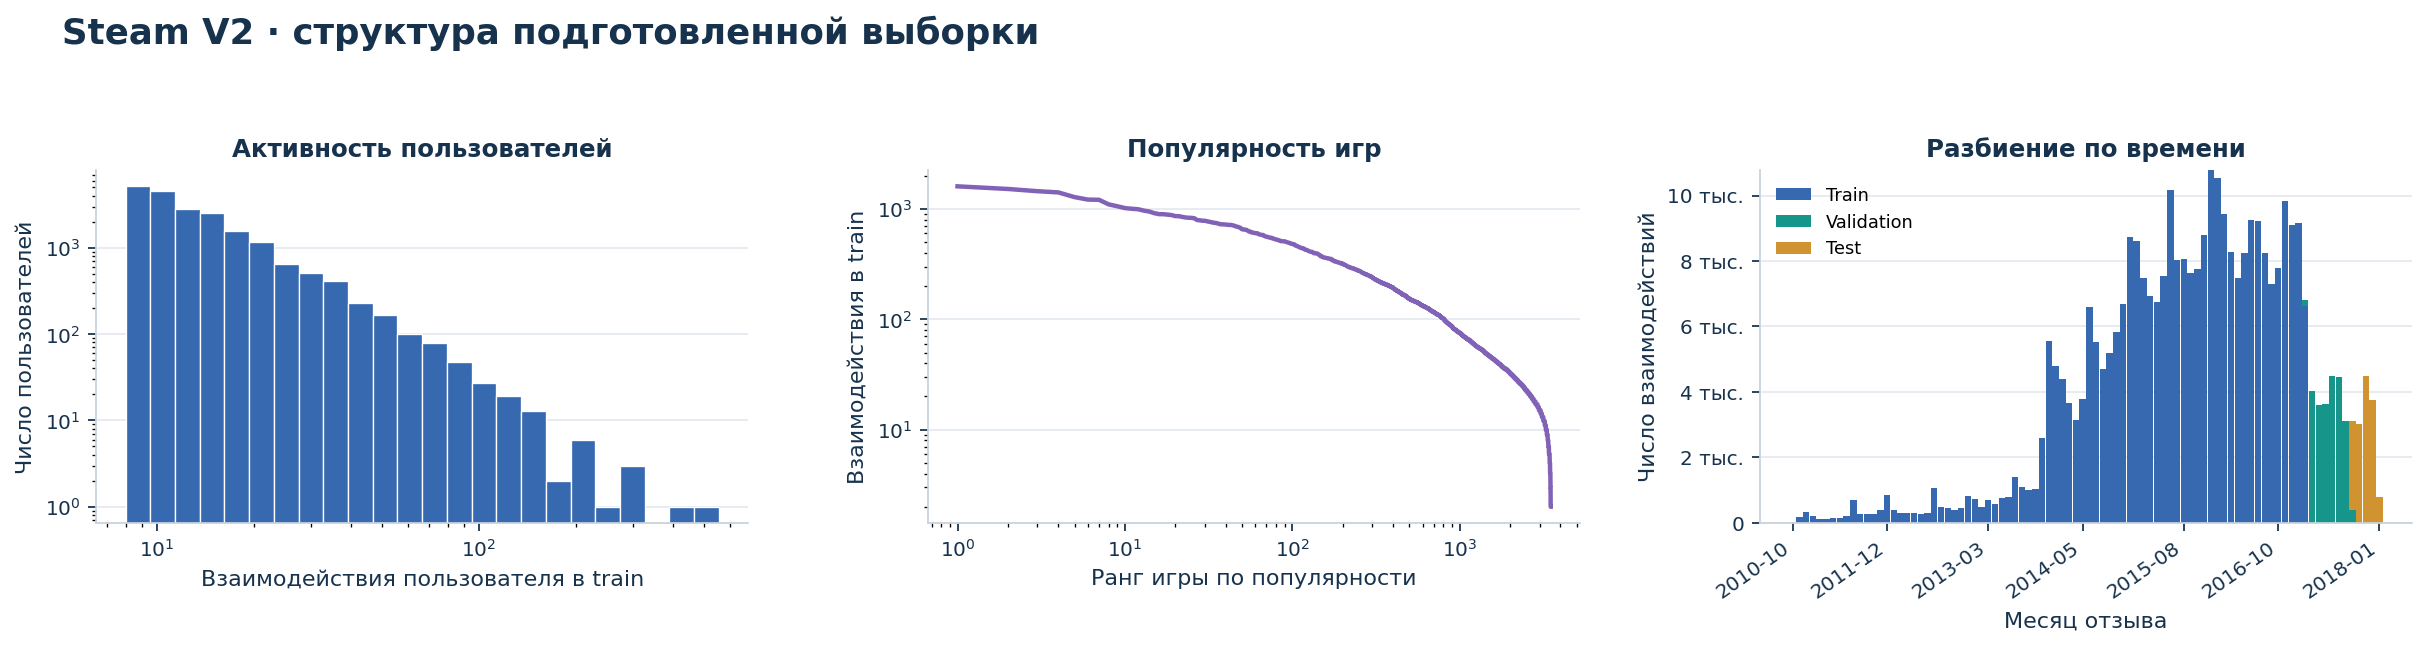

In [5]:
eda_table = pd.DataFrame({
    "Train: активность пользователя": data["eda"]["train_user_activity"],
    "Train: популярность игры": data["eda"]["train_item_popularity"],
    "Часы, только описательно": data["eda"]["hours_descriptive_only"],
})
display(eda_table)
hours_all = np.concatenate([data[f"{part}_hours"] for part in ("train", "val", "test")])
display(pd.DataFrame([{
    "Пропуски/некорректные hours среди валидных исходных строк": raw["missing_or_invalid_hours"],
    "Пропуски hours в итоговой выборке": int((~np.isfinite(hours_all)).sum()),
    "Доля пропусков hours в итоговой выборке": float((~np.isfinite(hours_all)).mean()),
}]))
display(pd.DataFrame(data["eda"]["top_train_items"]).rename(
    columns={"id": "Steam ID", "name": "Игра", "count": "Train-взаимодействия"}))
eda_figures = make_figures(data, [], [], ROOT)
display(Image(filename=str(ROOT / eda_figures["eda"])))

### Признаки для FM

Жанры, разработчик, издатель и `specs` доступны одним снимком без истории изменений, поэтому использую их только в EDA. Названия нужны для примеров рекомендаций.

FM получает ID пользователя, ID игры и два признака из истории отзывов $H$. Для момента рекомендации $T$:

$$
n_i(T)=\sum_{(u,i,t)\in H}\mathbf{1}[t<T],\qquad
b_i(T)=\lfloor\log_2 n_i(T)\rfloor,\qquad
y_i(T)=\operatorname{year}_{UTC}\!\left(\min_{(u,i,t)\in H:t<T}t\right).
$$

$b_i$ кодирует популярность: 1 отзыв, 2-3, 4-7 и так далее. $y_i$ отражает длину истории игры через год первого наблюдаемого отзыва, а не год выхода. Оба признака кодируются one-hot.

Для validation признаки и словарь строю по train, для test - по train + validation. Учитываются только события строго до $T$. В пределах одного обучения признаки игры одинаковы для всех положительных и отрицательных примеров.

,Поле снимка (только EDA),Доля заполнения
0,genres,0.995140
1,developer,0.987136
2,publisher,0.984277
3,specs,0.993997


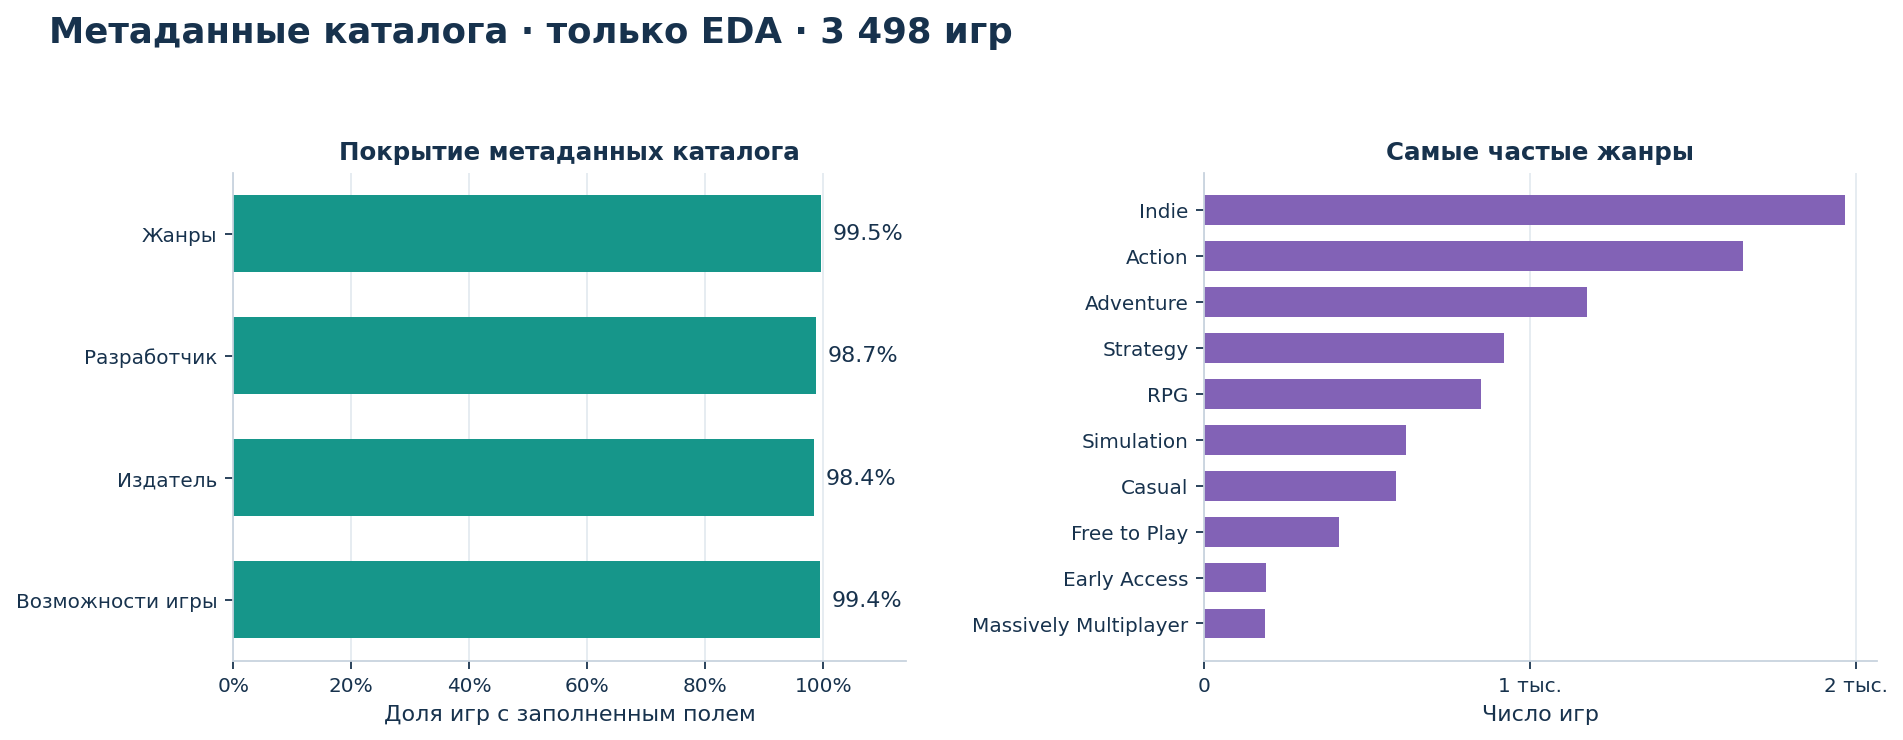

,Игр,Категорий FM,Активных категорий на игру
0,3498,18,2


,Категория FM (только train),Число игр
0,count_log2=1,16
1,count_log2=10,9
2,count_log2=2,101
3,count_log2=3,411
4,count_log2=4,927
5,count_log2=5,885
6,count_log2=6,527
7,count_log2=7,355
8,count_log2=8,190
9,count_log2=9,77


In [6]:
metadata_fields = ("genres", "developer", "publisher", "specs")
display(pd.DataFrame([{
    "Поле снимка (только EDA)": field,
    "Доля заполнения": np.mean([bool(row.get(field)) for row in data["item_metadata"]]),
} for field in metadata_fields]))
display(Image(filename=str(ROOT / eda_figures["metadata"])))

item_features, feature_names = build_item_features(
    data["train_items"], data["train_times"], data["n_items"],
    data["cutoff_train"], return_names=True,
)
assert sparse.isspmatrix_csr(item_features)
assert item_features.shape[0] == data["n_items"]
assert np.all(np.diff(item_features.indptr) == 2)
assert all(name.split("=", 1)[0] in ("count_log2", "first_review_year") for name in feature_names)
display(pd.DataFrame([{
    "Игр": item_features.shape[0], "Категорий FM": item_features.shape[1],
    "Активных категорий на игру": 2,
}]))
display(pd.DataFrame({
    "Категория FM (только train)": feature_names,
    "Число игр": np.asarray(item_features.sum(axis=0)).ravel().astype(int),
}))

## 3. Протокол оценки

Train содержит ранние отзывы, validation - следующий период, test - последний. Параметры подбираю на validation, затем обучаю модели на train + validation и оцениваю на test.

Правила общие для всех моделей:

- релевантны игры с отзывом пользователя в отложенном периоде;
- кандидаты - весь выбранный train-каталог, без сэмплирования;
- при оценке validation исключается история train, при оценке test - train + validation;
- оцениваются пользователи хотя бы с одним отложенным взаимодействием;
- при равных оценках выше ставится игра с меньшим Steam ID.

Пользователи и игры вне выбранной train-подвыборки не оцениваются. Cold start не рассматривается.

In [7]:
display(pd.DataFrame(data["stats"]["splits"]).T.rename(columns={
    "interactions": "Взаимодействия", "users": "Пользователи",
    "items": "Игры", "first_utc": "Начало UTC", "last_utc": "Конец UTC",
}))
display(pd.DataFrame([{
    "Граница": name,
    "Дата UTC": pd.to_datetime(data[key], unit="s", utc=True),
} for name, key in [("Train / validation", "cutoff_train"), ("Validation / test", "cutoff_val")]]))
for part in ("val", "test"):
    assert data["train_times"].max() < data[f"{part}_times"].min()
assert data["val_times"].max() < data["test_times"].min()
X_train, T_train = matrices(data)
X_train_val, T_train_val = matrices(data, include_validation=True)
Y_val, Y_test = truth_matrix(data, "val"), truth_matrix(data, "test")
assert X_train.multiply(Y_val).nnz == 0
assert X_train_val.multiply(Y_test).nnz == 0
assert X_train.nnz + Y_val.nnz + Y_test.nnz == total
display(Markdown(
    f"На validation оцениваются **{np.count_nonzero(np.diff(Y_val.indptr)):,}** пользователей; "
    f"на test - **{np.count_nonzero(np.diff(Y_test.indptr)):,}**. "
    "В каждой части набор пользователей одинаков для всех моделей."
))

,Взаимодействия,Пользователи,Игры,Начало UTC,Конец UTC
train,308375,20000,3498,2010-10-15T00:00:00+00:00,2017-02-27T00:00:00+00:00
val,23908,8251,2937,2017-02-28T00:00:00+00:00,2017-09-03T00:00:00+00:00
test,14767,6227,2606,2017-09-04T00:00:00+00:00,2018-01-05T00:00:00+00:00


,Граница,Дата UTC
0,Train / validation,2017-02-28 00:00:00+00:00
1,Validation / test,2017-09-04 00:00:00+00:00


На validation оцениваются **8,251** пользователей; на test - **6,227**. В каждой части набор пользователей одинаков для всех моделей.

### Метрики

$R_u$ - релевантные игры пользователя, $i_1,\ldots,i_{10}$ - рекомендации, $h_{uj}=\mathbf{1}[i_j\in R_u]$.

$$
\operatorname{Recall@10}_u=\frac{\sum_{j=1}^{10}h_{uj}}{|R_u|},\qquad
\operatorname{DCG@10}_u=\sum_{j=1}^{10}\frac{h_{uj}}{\log_2(j+1)},
$$

$$
\operatorname{NDCG@10}_u=\frac{\operatorname{DCG@10}_u}
{\sum_{j=1}^{\min(10,|R_u|)}1/\log_2(j+1)}.
$$

Перед подбором выбираю основную метрику **NDCG@10**: попадания в начале списка важнее. **Recall@10** показывает долю найденных будущих игр. При усреднении пользователи имеют одинаковый вес.

Также считаю Precision@10 - долю попаданий среди десяти рекомендаций, и Coverage@10 - долю каталога, встретившуюся хотя бы в одной выдаче.

## 4. Модели

### ItemKNN

Для бинарной матрицы $X$ обозначим $n_i=\sum_u X_{ui}$ и $c_{ij}=\sum_u X_{ui}X_{uj}$. Использую cosine similarity со shrinkage:

$$
S_{ij}=\frac{c_{ij}}{\sqrt{n_i n_j}}\frac{c_{ij}}{c_{ij}+\beta},\qquad S_{ii}=0.
$$

Для каждой игры $j$ оставляю $k$ ближайших соседей и считаю $s(u,j)=\sum_i X_{ui}S_{ij}$. Shrinkage уменьшает влияние редких совпадений.

Реализация: `models/itemknn.py`.

### iALS

Для неявной обратной связи $p_{ui}=X_{ui}$, $c_{ui}=1+\alpha X_{ui}$. Ошибка считается по всем парам, включая ненаблюдавшиеся:

$$
\min_{A,B}\sum_{u,i}c_{ui}(p_{ui}-a_u^\top b_i)^2
+\lambda\left(\sum_u\|a_u\|_2^2+\sum_i\|b_i\|_2^2\right).
$$

Факторы пользователей и игр обновляются по очереди. При фиксированных факторах игр $B$:

$$
a_u=\left(B^\top B+\alpha\sum_{i:X_{ui}=1}b_i b_i^\top+\lambda I\right)^{-1}
\sum_{i:X_{ui}=1}(1+\alpha)p_{ui}b_i.
$$

Для игр обновление аналогично. Решаю линейные системы без явного обращения матриц.

Реализация: `models/ials.py`.

### EASE

EASE восстанавливает историю пользователя через линейные связи между играми:

$$
\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2,\qquad \operatorname{diag}(B)=0.
$$

Решение:

$$
P=(X^\top X+\lambda I)^{-1},\qquad B_{ij}=-P_{ij}/P_{jj},\qquad B_{jj}=0.
$$

Оценки равны $XB$. Нулевая диагональ запрещает копировать вход. Использую разложение Холецкого; плотная матрица весов требует памяти, растущей как квадрат числа игр.

Реализация: `models/ease.py`.

### FM с метапризнаками

Вектор $z$ содержит ID пользователя, ID игры и две one-hot категории из истории игры:

$$
f(z)=w_0+\sum_j w_jz_j+\sum_{j<k}\langle v_j,v_k\rangle z_jz_k.
$$

Парные взаимодействия вычисляю без явного перебора:

$$
\sum_{j<k}\langle v_j,v_k\rangle z_jz_k=
\frac12\sum_f\left[\left(\sum_jv_{jf}z_j\right)^2-\sum_jv_{jf}^2z_j^2\right].
$$

Для отзывов ставлю $y=1$, для случайных игр вне обучающей истории пользователя - $y=0$. Негативы выбираются заново каждую эпоху. Будущая история не используется, поэтому среди них могут быть будущие релевантные игры.

Обучение: BCE по logits, Adam и L2-регуляризация. Формула и цикл обучения написаны в `models/fm.py`, градиенты считает PyTorch.

### RecencyALS

Проверяю гипотезу: недавние отзывы лучше отражают текущий интерес. Снижаю таргет старых отзывов, сохраняя положительный сигнал:

$$
p^{\mathrm{rec}}_{ui}=\begin{cases}
0.25+0.75\cdot2^{-(T-t_{ui})/(86400H)},&X_{ui}=1,\\
0,&X_{ui}=0.
\end{cases}
$$

$T$ - начало оцениваемого периода, $t_{ui}$ - дата отзыва в секундах, $H$ - период полураспада в днях. У свежего отзыва таргет близок к 1, у старого стремится к 0.25.

Меняется только таргет $p_{ui}$. Confidence остаётся $c_{ui}=1+\alpha X_{ui}$. Размерность, регуляризация, итерации и seed совпадают с выбранным iALS; отдельно подбираю только $H$.

Реализация: `models/custom_als.py`.

### Дополнительные сравнения

**MostPopular** ранжирует игры по числу пользователей в обучающей части.

**FM_ID** - выбранная FM без метапризнаков. Seed, начальные ID-факторы, негативы и порядок обучения совпадают. Отдельного подбора нет: сравнение показывает эффект признаков при фиксированных настройках.

## 5. Подбор параметров

Перебираю сетки из `config.json` и выбираю максимум validation NDCG@10. При равенстве беру первый вариант сетки.

Для RecencyALS фиксирую параметры лучшего iALS и перебираю $H\in\{90,365,1095\}$ дней.

In [8]:
assert CONFIG["primary_metric"] == "ndcg@10"
grid_rows = []
for model_name, trials in CONFIG["grids"].items():
    for trial_id, params in enumerate(trials, 1):
        grid_rows.append({"Модель": model_name, "Вариант": trial_id,
                          "Параметры": json.dumps(params, ensure_ascii=False, sort_keys=True)})
for trial_id, half_life in enumerate(CONFIG["custom_half_lives_days"], 1):
    grid_rows.append({"Модель": "RecencyALS", "Вариант": trial_id,
                      "Параметры": f"best validation iALS + half_life_days={half_life}; floor={CONFIG['custom_target_floor']}"})
display(pd.DataFrame(grid_rows))
display(Markdown(
    f"Seed: **{SEED}**. Основная метрика: **{CONFIG['primary_metric']}**. "
    f"Число подбираемых вариантов: **{len(grid_rows)}**. "
))

,Модель,Вариант,Параметры
0,ItemKNN,1,"{""neighbors"": 50, ""shrinkage"": 10.0}"
1,ItemKNN,2,"{""neighbors"": 100, ""shrinkage"": 10.0}"
2,ItemKNN,3,"{""neighbors"": 200, ""shrinkage"": 10.0}"
3,ItemKNN,4,"{""neighbors"": 100, ""shrinkage"": 50.0}"
4,EASE,1,"{""regularization"": 50.0}"
5,EASE,2,"{""regularization"": 200.0}"
6,EASE,3,"{""regularization"": 1000.0}"
7,iALS,1,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 12, ""regularization"": 1.0}"
8,iALS,2,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 12, ""regularization"": 10.0}"
9,iALS,3,"{""alpha"": 20.0, ""factors"": 64, ""iterations"": 12, ""regularization"": 10.0}"


Seed: **42**. Основная метрика: **ndcg@10**. Число подбираемых вариантов: **16**. 

### Результаты на validation

In [9]:
with redirect_stdout(io.StringIO()):
    validation_rows, best_params = run_validation(data, ROOT, force=False)
validation_table = pd.DataFrame([
    {key: value for key, value in row.items() if key != "history"}
    for row in validation_rows
])
validation_table["params"] = validation_table["params"].map(lambda value: json.dumps(value, sort_keys=True))
display(validation_table[["model", "trial", "ndcg@10", "recall@10", "precision@10", "coverage@10",
                          "n_users", "fit_seconds", "eval_seconds", "params"]].sort_values(
                              ["model", "ndcg@10"], ascending=[True, False]))

,model,trial,ndcg@10,recall@10,precision@10,coverage@10,n_users,fit_seconds,eval_seconds,params
5,EASE,2,0.039354,0.062192,0.016374,0.320755,8251,1.366636,6.704201,"{""regularization"": 200.0}"
4,EASE,1,0.039342,0.061691,0.015816,0.430532,8251,1.275147,6.538008,"{""regularization"": 50.0}"
6,EASE,3,0.037324,0.058886,0.015489,0.217267,8251,1.278661,6.686819,"{""regularization"": 1000.0}"
10,FM,1,0.026177,0.038859,0.010362,0.077473,8251,13.555795,1.705503,"{""batch_size"": 2048, ""epochs"": 8, ""factors"": 16, ""learning_rate"": 0.01, ""negative_ratio"": 2, ""regularization"": 1e-05}"
11,FM,2,0.025812,0.037207,0.009975,0.075472,8251,16.123447,1.752171,"{""batch_size"": 2048, ""epochs"": 8, ""factors"": 32, ""learning_rate"": 0.01, ""negative_ratio"": 2, ""regularization"": 1e-05}"
12,FM,3,0.018871,0.030690,0.007623,0.011149,8251,11.853636,1.682585,"{""batch_size"": 2048, ""epochs"": 8, ""factors"": 16, ""learning_rate"": 0.003, ""negative_ratio"": 2, ""regularization"": 0.0001}"
17,FM_ID,1,0.028727,0.043070,0.011053,0.064037,8251,9.193577,1.707015,"{""batch_size"": 2048, ""epochs"": 8, ""factors"": 16, ""learning_rate"": 0.01, ""negative_ratio"": 2, ""regularization"": 1e-05}"
1,ItemKNN,2,0.037164,0.058720,0.015525,0.390509,8251,0.452744,1.454553,"{""neighbors"": 100, ""shrinkage"": 10.0}"
2,ItemKNN,3,0.036942,0.058028,0.015368,0.353059,8251,0.523519,1.817145,"{""neighbors"": 200, ""shrinkage"": 10.0}"
0,ItemKNN,1,0.036846,0.057747,0.015344,0.427673,8251,0.455833,1.116814,"{""neighbors"": 50, ""shrinkage"": 10.0}"


,Модель,Выбранные параметры
0,ItemKNN,"{""neighbors"": 100, ""shrinkage"": 10.0}"
1,EASE,"{""regularization"": 200.0}"
2,iALS,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 12, ""regularization"": 10.0}"
3,FM,"{""batch_size"": 2048, ""epochs"": 8, ""factors"": 16, ""learning_rate"": 0.01, ""negative_ratio"": 2, ""regularization"": 1e-05}"
4,RecencyALS,"{""alpha"": 20.0, ""factors"": 32, ""floor"": 0.25, ""half_life_days"": 90, ""iterations"": 12, ""regularization"": 10.0}"
5,MostPopular,{}
6,FM_ID,"{""batch_size"": 2048, ""epochs"": 8, ""factors"": 16, ""learning_rate"": 0.01, ""negative_ratio"": 2, ""regularization"": 1e-05}"


На validation лучшая NDCG@10 у **RecencyALS**: **0.04430**. 

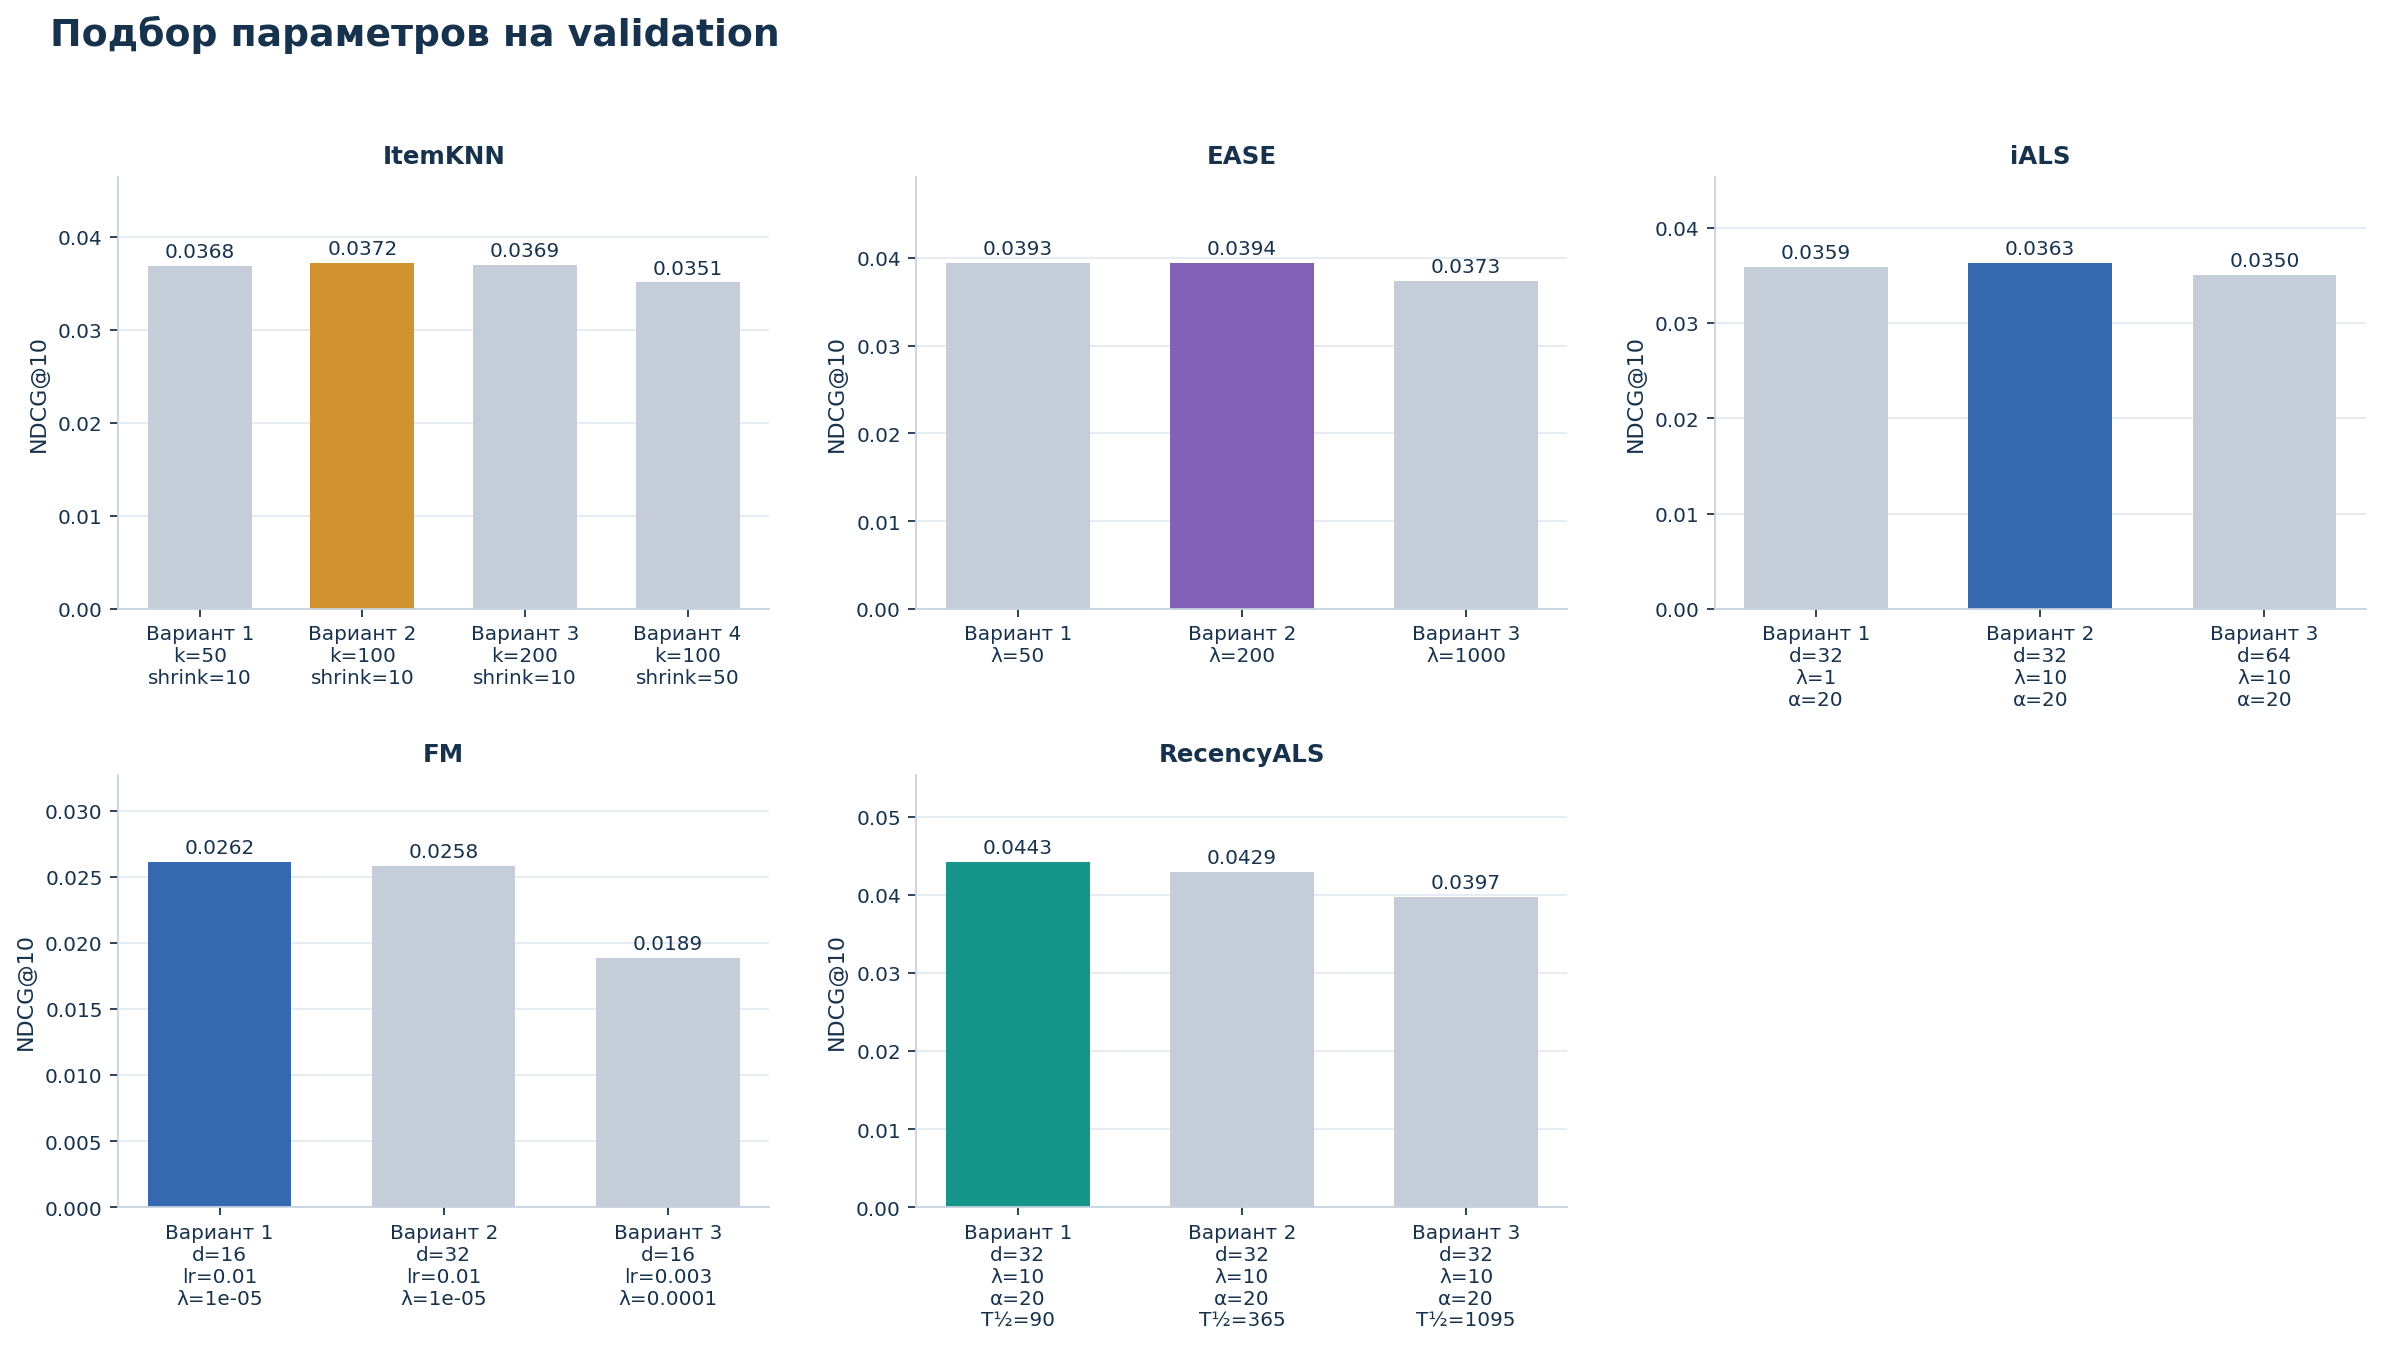

In [10]:
selection = read_json(ROOT / "artifacts" / "selected_parameters.json")
assert selection["test_used_for_selection"] is False
assert selection["fingerprint"] == fingerprint(ROOT)
display(pd.DataFrame([{"Модель": name, "Выбранные параметры": json.dumps(params, sort_keys=True)}
                      for name, params in best_params.items()]))
assert all(best_params["RecencyALS"][key] == value for key, value in best_params["iALS"].items())
assert best_params["FM_ID"] == best_params["FM"]
selected_val = []
for name, params in best_params.items():
    matching = [row for row in validation_rows if row["model"] == name and row["params"] == params]
    assert matching
    selected_val.append(matching[0])
best_validation_model = max(selected_val, key=lambda row: row["ndcg@10"])
display(Markdown(
    f"На validation лучшая NDCG@10 у "
    f"**{best_validation_model['model']}**: **{best_validation_model['ndcg@10']:.5f}**. "
))
validation_figures = make_figures(data, validation_rows, [], ROOT)
display(Image(filename=str(ROOT / validation_figures["validation"])))

## 6. Сравнение на test

Финальная оценка после переобучения на train + validation с параметрами, выбранными на validation.

In [11]:
with redirect_stdout(io.StringIO()):
    final_rows = run_final(data, ROOT, force=False)
final_manifest = read_json(ROOT / "artifacts" / "final_manifest.json")
assert final_manifest["test_used_for_selection"] is False
assert final_manifest["fingerprint"] == fingerprint(ROOT)
final_table = pd.DataFrame([
    {key: value for key, value in row.items() if key not in ("history", "target_summary")}
    for row in final_rows
]).sort_values("ndcg@10", ascending=False)
final_table["params"] = final_table["params"].map(lambda value: json.dumps(value, sort_keys=True))
mandatory = {"ItemKNN", "iALS", "EASE", "FM", "RecencyALS"}
assert mandatory.issubset(set(final_table["model"]))
assert set(final_table["model"]) == mandatory | {"MostPopular", "FM_ID"}
assert final_table["n_users"].nunique() == 1
display(final_table[["model", "ndcg@10", "recall@10", "precision@10", "coverage@10",
                     "n_users", "fit_seconds", "eval_seconds", "params"]].reset_index(drop=True))

,model,ndcg@10,recall@10,precision@10,coverage@10,n_users,fit_seconds,eval_seconds,params
0,RecencyALS,0.040076,0.067814,0.014293,0.233562,6227,9.862022,1.276626,"{""alpha"": 20.0, ""factors"": 32, ""floor"": 0.25, ""half_life_days"": 90, ""iterations"": 12, ""regularization"": 10.0}"
1,EASE,0.039283,0.067533,0.014469,0.314465,6227,1.335218,5.056008,"{""regularization"": 200.0}"
2,ItemKNN,0.035779,0.060374,0.013088,0.355346,6227,0.515853,1.175793,"{""neighbors"": 100, ""shrinkage"": 10.0}"
3,iALS,0.034730,0.059836,0.012799,0.248714,6227,9.743819,1.284713,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 12, ""regularization"": 10.0}"
4,MostPopular,0.032860,0.043124,0.008495,0.006289,6227,0.006771,1.057119,{}
5,FM_ID,0.032061,0.050832,0.010487,0.061464,6227,9.654921,1.308298,"{""batch_size"": 2048, ""epochs"": 8, ""factors"": 16, ""learning_rate"": 0.01, ""negative_ratio"": 2, ""regularization"": 1e-05}"
6,FM,0.023171,0.041614,0.008800,0.092338,6227,13.369926,1.312447,"{""batch_size"": 2048, ""epochs"": 8, ""factors"": 16, ""learning_rate"": 0.01, ""negative_ratio"": 2, ""regularization"": 1e-05}"


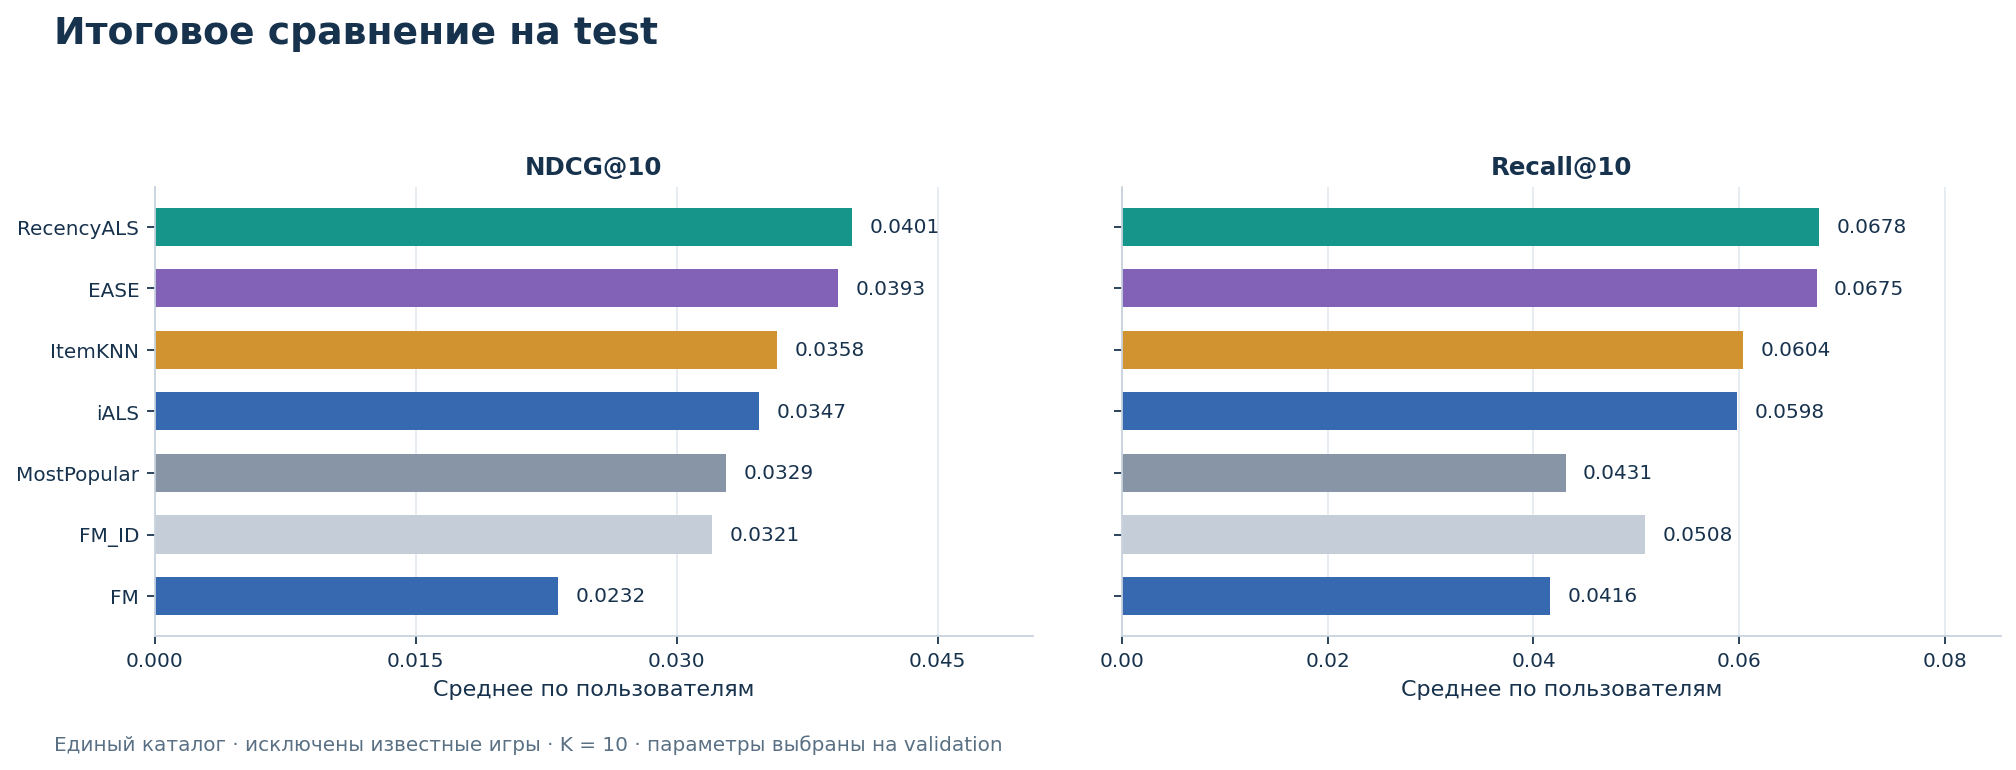

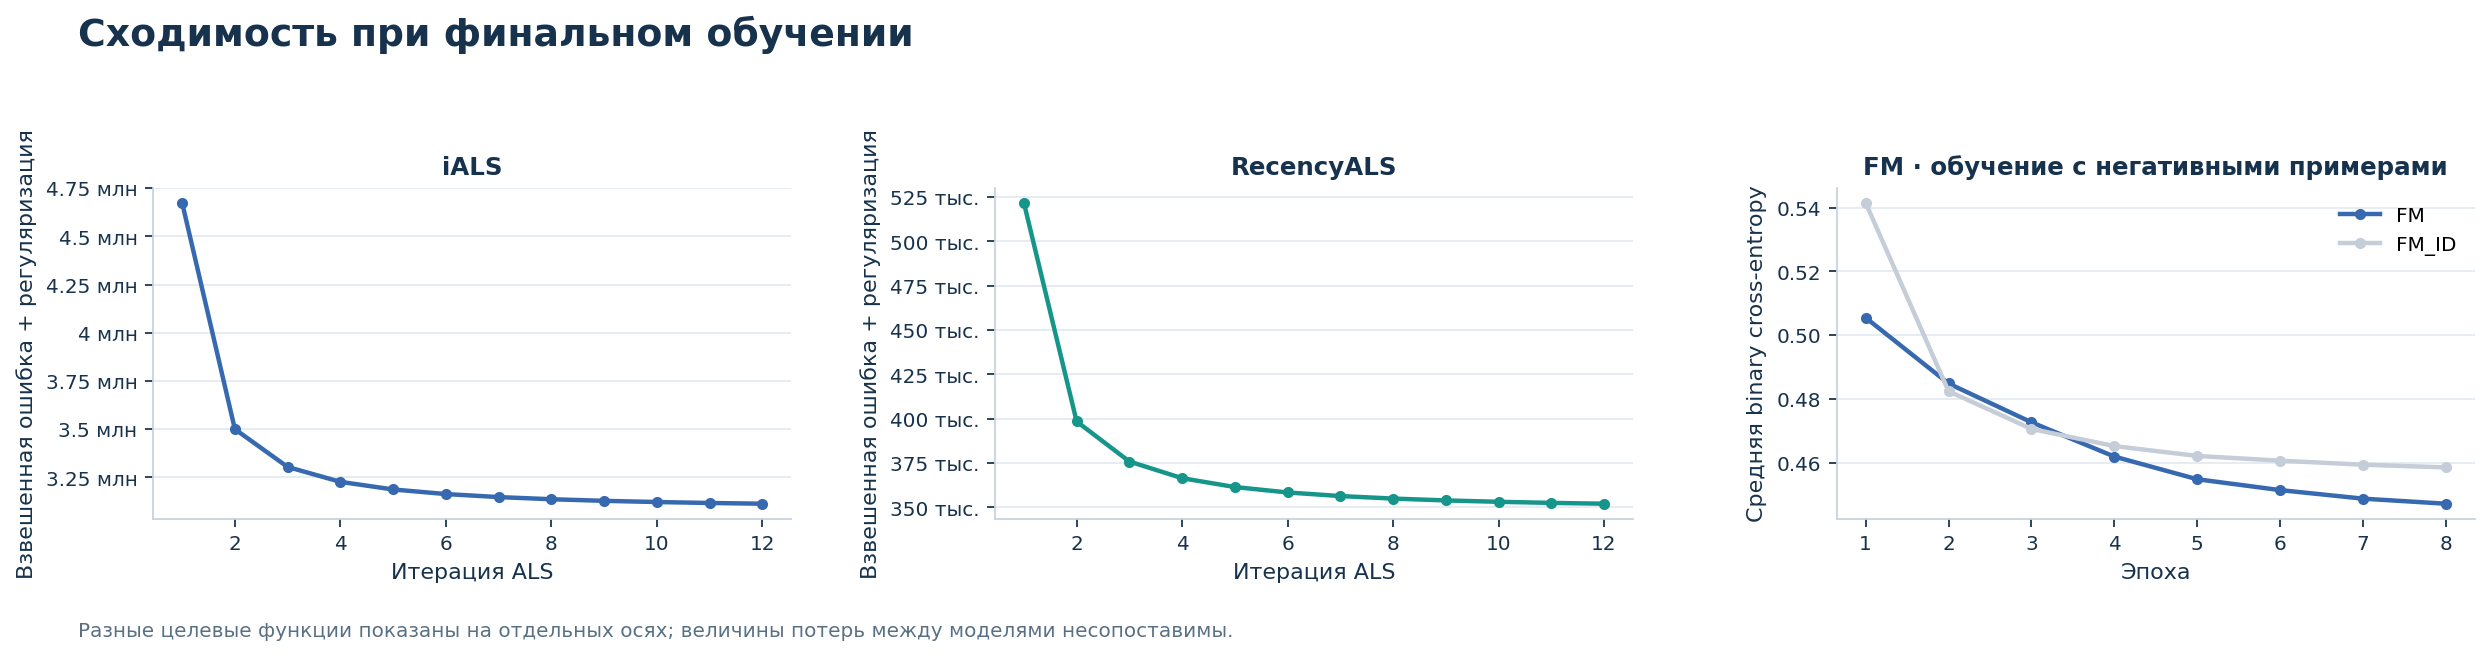

In [12]:
figures = generate_figures(data, ROOT)
display(Image(filename=str(ROOT / figures["final_metrics"])))
if "training" in figures:
    display(Image(filename=str(ROOT / figures["training"])))

### Эффект давности и метапризнаков

Сравниваю RecencyALS - iALS, FM - FM_ID и EASE - MostPopular по разности NDCG@10. Строю 95%-е парные bootstrap-интервалы: 2000 выборок пользователей с возвращением, seed=42.

Если интервал включает ноль, оснований говорить об устойчивом различии недостаточно. Интервалы описывают вариацию пользователей только в этом test-периоде.

In [13]:
paired = read_json(ROOT / "artifacts" / "paired_comparisons.json")
display(pd.DataFrame(paired)[["comparison", "mean_difference", "ci_low", "ci_high"]].rename(
    columns={"comparison": "Сравнение", "mean_difference": "Разность NDCG@10",
             "ci_low": "Нижняя граница", "ci_high": "Верхняя граница"}))
indexed_results = {row["model"]: row for row in final_rows}

,Сравнение,Разность NDCG@10,Нижняя граница,Верхняя граница
0,RecencyALS - iALS,0.005345,0.002301,0.008354
1,FM - FM_ID,-0.008890,-0.011305,-0.006473
2,EASE - MostPopular,0.006423,0.002628,0.010551


### Примеры рекомендаций

Выдачи EASE и RecencyALS для первых трёх test-пользователей, без отбора по числу попаданий. Показано до 15 известных игр в порядке ID, в top-10 отмечены совпадения с test.

Отсутствие будущего отзыва не доказывает, что рекомендация неинтересна.

In [14]:
for model_name in ("EASE", "RecencyALS"):
    examples = read_json(ROOT / "artifacts" / f"examples_{model_name}.json")
    display(Markdown(f"### {model_name}"))
    for example in examples:
        display(Markdown(f"**Пользователь #{example['user_index']}**"))
        display(pd.DataFrame({
            "Известные игры (до 15, по ID)": pd.Series(example["history"]),
            "Релевантные будущие игры": pd.Series(example["held_out_relevant"]),
        }))
        recommendations = pd.DataFrame(example["top10"])
        recommendations.insert(0, "Позиция", np.arange(1, len(recommendations) + 1))
        display(recommendations.rename(columns={"game": "Игра", "hit": "Есть будущий отзыв"}))

### EASE

**Пользователь #4**

,"Известные игры (до 15, по ID)",Релевантные будущие игры
0,Homefront,Killing Floor 2
1,Call of Duty®: Ghosts,NaN
2,Alien: Isolation,NaN
3,Tom Clancy’s Splinter Cell Blacklist,NaN
4,HITMAN™,NaN
5,Deus Ex: Human Revolution - Director's Cut,NaN
6,Dying Light,NaN
7,Castlevania: Lords of Shadow 2,NaN
8,Homeworld Remastered Collection,NaN
9,Deus Ex: The Fall,NaN


,Позиция,Игра,Есть будущий отзыв
0,1,Deus Ex: Mankind Divided,False
1,2,Call of Duty®: Advanced Warfare - Gold Edition,False
2,3,Hitman: Absolution™,False
3,4,Wolfenstein: The New Order,False
4,5,Ryse: Son of Rome,False
5,6,Sniper Elite 3,False
6,7,Castlevania: Lords of Shadow - Ultimate Edition,False
7,8,Spec Ops: The Line,False
8,9,Batman™: Arkham Origins,False
9,10,Evolve Stage 2,False


**Пользователь #7**

...

,"Известные игры (до 15, по ID)",Релевантные будущие игры
0,Castle of Illusion,The Room
1,Starpoint Gemini 2,Endless Space® 2
2,The Banner Saga,NaN
3,Hammerwatch,NaN
4,Rogue Legacy,NaN
5,Dungeon of the Endless™,NaN
6,FortressCraft Evolved!,NaN
7,The Last Federation,NaN
8,No Man's Sky,NaN
9,Vertical Drop Heroes HD,NaN


,Позиция,Игра,Есть будущий отзыв
0,1,Killing Floor 2,False
1,2,The Beginner's Guide,False
2,3,Rebel Galaxy,False
3,4,Transistor,False
4,5,Wolfenstein: The New Order,False
5,6,Hand of Fate,False
6,7,Red Faction Guerrilla Steam Edition,False
7,8,RimWorld,False
8,9,Endless Legend™,False
9,10,Dying Light,False


**Пользователь #15**

,"Известные игры (до 15, по ID)",Релевантные будущие игры
0,Gas Guzzlers Extreme,FlatOut: Ultimate Carnage
1,Zigfrak,Sleeping Dogs
2,Void Destroyer,How to Survive
3,Platformines,The Plan
4,Batman™: Arkham Origins Blackgate - Deluxe Edition,Sparkle 2 Evo
5,No Man's Sky,Evolve Stage 2
6,Dead Effect,Fahrenheit: Indigo Prophecy Remastered
7,Shroud of the Avatar: Forsaken Virtues,Hatred
8,Steam Controller,Samorost 3
9,The Deadly Tower of Monsters,NaN


,Позиция,Игра,Есть будущий отзыв
0,1,Half-Life 2,False
1,2,Portal 2,False
2,3,The Beginner's Guide,False
3,4,Shadow Warrior 2,False
4,5,Half-Life 2: Episode One,False
5,6,Conan Exiles,False
6,7,Rust,False
7,8,Brothers - A Tale of Two Sons,False
8,9,Red Faction Guerrilla Steam Edition,False
9,10,Life is Strange - Episode 1,False


### Время обучения

Время исходного финального обучения и оценки на CPU с лимитом 2 потока.

In [15]:
runtime_table = pd.DataFrame([
    {"Модель": row["model"], "Обучение, с": row["fit_seconds"],
     "Оценка, с": row["eval_seconds"]}
    for row in final_rows
])
display(runtime_table.round(2))

,Модель,"Обучение, с","Оценка, с"
0,ItemKNN,0.52,1.18
1,iALS,9.74,1.28
2,EASE,1.34,5.06
3,FM,13.37,1.31
4,RecencyALS,9.86,1.28
5,MostPopular,0.01,1.06
6,FM_ID,9.65,1.31


## 7. Выводы

Лучший результат у **RecencyALS** с 32 факторами и $H=90$ дней: NDCG@10 = **0.04008**, Recall@10 = **0.06781**. EASE с $\lambda=200$ близка по обеим метрикам.

При одинаковых настройках RecencyALS улучшила NDCG@10 базового iALS на **15.4%**. Парный интервал разности целиком выше нуля: учёт давности помог на этой выборке.

FM с историческими признаками уступила FM_ID на **27.7%** по NDCG@10: **0.02317** против **0.03206**. Интервал разности **[-0.011305; -0.006473]** целиком ниже нуля. В выбранной конфигурации популярность и год первого отзыва не помогли.

Быстрее всех из пяти основных моделей обучилась **ItemKNN**: **0.52 с**.

### Ограничения

- Отзыв отражает взаимодействие, но не обязательно удовлетворённость игрой.
- Выбраны активные пользователи и популярные игры; cold start и редкие игры не исследованы.
- Метапризнаки описывают историю отзывов, а не содержание игр.
- Использованы один test-период, один seed и небольшие сетки. Вывод о FM относится к выбранным признакам и бюджету обучения.